# 27. KAMP 추천 타점의 이탈 방향 대조 (작업 4·5)
- 입력: `results/final_kamp_recommendations_combined.csv`(결합 사양 추천, 수정하지 않음). 복사 블록(상태 = 품질확인) 행은 뺀다.
- 추천 묶음: A등급, A+B등급, 상위 10%(`추천_10%`). 비교 대상은 같은 날 순위 대상 중 그 묶음에 들지 않은 나머지.
- 방향: 그날(순위 대상 행) 중앙값보다 높음/같음/낮음. KAMP 값은 0.01 단위로 기록돼 같음이 많다(통전시간 56%).
- 입열량은 KAMP에 전압이 있으므로 V·I·t(1장 정의)를 쓰고, Querétaro와 같은 대리값 I²·t도 함께 낸다.
- **의심 불량 유형 규칙은 26번 Querétaro 결과와 문헌으로 먼저 정한 뒤 적용한다**(아래 RULES). 단, README의 "결합 10% 추천의 83%는 전류가 낮다"는 이미 알려진 사실이다.
- 추천 타점은 모델이 고른 것이다. 조건 차이는 "불량 원인"이 아니라 "현장에서 확인할 가설"이다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from scipy import stats
import br
from br import plot as P, stat as T
from wl import data as wldata
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
K = pd.read_csv(br.RES / "final_kamp_recommendations_combined.csv")
K = K[K.상태 == "순위 부여"].copy()
K["cur"], K["vol"], K["time"], K["force"] = K["weld current(kA)"], K["weld Voltage(v)"], K["weld time(ms)"], K["weld force(bar)"]
K["heat"] = K.vol * K.cur * K.time; K["i2t"] = K.cur ** 2 * K.time; K["IF"] = K.cur / K.force; K["dynres"] = K.vol / K.cur
VARS = [("cur", "전류"), ("time", "통전시간"), ("force", "가압력"), ("heat", "입열량 V·I·t"), ("i2t", "입열 대리값 I²·t"), ("IF", "전류/가압력"), ("dynres", "동저항 V/I(참고)")]
for c, _ in VARS:
    med = K.groupby("date")[c].transform("median")
    K[f"{c}_dir"] = np.sign(np.round(K[c] - med, 10)).astype(int)            # +1 높음, 0 같음, −1 낮음
    mad = (K[c] - med).abs().groupby(K.date).transform("median") * 1.4826
    K[f"{c}_z"] = (K[c] - med) / mad.replace(0, np.nan)
K["grpA"] = K["결합 등급"] == "A"; K["grpAB"] = K["결합 등급"].isin(["A", "B"]); K["grp10"] = K["추천_10%"].astype(bool)
GROUPS = [("grpA", "A등급"), ("grpAB", "A+B등급"), ("grp10", "상위 10%")]
print("순위 대상 타점:", len(K), "| 묶음 크기:", {nm: int(K[g].sum()) for g, nm in GROUPS})

순위 대상 타점: 10775 | 묶음 크기: {'A등급': 45, 'A+B등급': 225, '상위 10%': 1079}


## 1. 추천 묶음별 이탈 방향 비율 (작업 4)
비율 차이의 95% 구간은 타점이 서로 독립이라고 가정한 Newcombe 구간이다. KAMP 전류는 생산 순서상 자기상관(시차 1에서 0.95)이 커서 **실제 불확실성은 이보다 크다.**
그래서 9일 중 며칠에서 같은 방향이 나왔는지(날짜별 일관성)를 함께 본다.

In [2]:
rows = []
for g, gname in GROUPS:
    for c, cname in VARS:
        a, b = K[K[g]], K[~K[g]]
        r = {"묶음": gname, "변수": cname, "n(묶음)": len(a), "n(나머지)": len(b)}
        for v, lab in ((-1, "낮음"), (0, "같음"), (1, "높음")):
            r[f"{lab}%(묶음)"] = (a[f"{c}_dir"] == v).mean() * 100; r[f"{lab}%(나머지)"] = (b[f"{c}_dir"] == v).mean() * 100
        for v, lab in ((-1, "낮음"), (1, "높음")):
            d, lo, hi = T.newcombe((a[f"{c}_dir"] == v).sum(), len(a), (b[f"{c}_dir"] == v).sum(), len(b))
            r[f"{lab} 차이 %p [95%, 독립가정]"] = f"{d*100:+.1f} [{lo*100:+.1f}, {hi*100:+.1f}]"
        dd = K.groupby("date").apply(lambda x: (x[x[g]][f"{c}_dir"] == -1).mean() - (x[~x[g]][f"{c}_dir"] == -1).mean())
        r["낮음 비율이 나머지보다 큰 날"] = f"{int((dd > 0).sum())}/{dd.notna().sum()}"
        r["뚜렷이 낮음(z≤−1)%(묶음)"] = (a[f"{c}_z"] <= -1).mean() * 100; r["뚜렷이 낮음%(나머지)"] = (b[f"{c}_z"] <= -1).mean() * 100
        r["뚜렷이 높음(z≥+1)%(묶음)"] = (a[f"{c}_z"] >= 1).mean() * 100; r["뚜렷이 높음%(나머지)"] = (b[f"{c}_z"] >= 1).mean() * 100
        rows.append(r)
D = pd.DataFrame(rows).round(1)
D.to_csv(br.RES / "kamp_direction_by_group.csv", index=False, encoding="utf-8-sig")
display(D[["묶음", "변수", "n(묶음)", "낮음%(묶음)", "같음%(묶음)", "높음%(묶음)", "낮음%(나머지)", "같음%(나머지)", "높음%(나머지)", "낮음 차이 %p [95%, 독립가정]", "낮음 비율이 나머지보다 큰 날"]])
display(D[["묶음", "변수", "뚜렷이 낮음(z≤−1)%(묶음)", "뚜렷이 낮음%(나머지)", "뚜렷이 높음(z≥+1)%(묶음)", "뚜렷이 높음%(나머지)"]])
print("묶음별 그날 중앙값 대비 차이의 중앙값:")
display(pd.DataFrame({gname: {cname: float((K[K[g]][c] - K.groupby("date")[c].transform("median")[K[g]]).median()) for c, cname in VARS} for g, gname in GROUPS}).round(4))

,묶음,변수,n(묶음),낮음%(묶음),같음%(묶음),높음%(묶음),낮음%(나머지),같음%(나머지),높음%(나머지),"낮음 차이 %p [95%, 독립가정]",낮음 비율이 나머지보다 큰 날
0,A등급,전류,45,91.1,0.0,8.9,46.9,9.3,43.8,"+44.2 [+32.3, +49.6]",8/9
1,A등급,통전시간,45,77.8,22.2,0.0,33.2,56.4,10.4,"+44.6 [+30.5, +54.3]",9/9
2,A등급,가압력,45,17.8,6.7,75.6,42.8,13.6,43.5,"-25.1 [-33.6, -11.5]",2/9
3,A등급,입열량 V·I·t,45,91.1,0.0,8.9,49.7,0.2,50.0,"+41.4 [+29.5, +46.8]",8/9
4,A등급,입열 대리값 I²·t,45,91.1,0.0,8.9,48.3,3.2,48.4,"+42.8 [+30.9, +48.2]",8/9
5,A등급,전류/가압력,45,86.7,0.0,13.3,48.9,1.9,49.2,"+37.7 [+24.8, +44.9]",8/9
6,A등급,동저항 V/I(참고),45,0.0,0.0,100.0,49.8,1.0,49.2,"-49.8 [-50.8, -41.9]",0/9
7,A+B등급,전류,225,95.1,0.9,4.0,46.1,9.4,44.5,"+49.0 [+45.2, +51.3]",9/9
8,A+B등급,통전시간,225,64.0,32.0,4.0,32.7,56.8,10.5,"+31.3 [+24.7, +37.3]",8/9
9,A+B등급,가압력,225,17.3,6.2,76.4,43.3,13.8,43.0,"-25.9 [-30.4, -20.4]",3/9


,묶음,변수,뚜렷이 낮음(z≤−1)%(묶음),뚜렷이 낮음%(나머지),뚜렷이 높음(z≥+1)%(묶음),뚜렷이 높음%(나머지)
0,A등급,전류,68.9,25.9,8.9,17.6
1,A등급,통전시간,0.0,0.0,0.0,0.0
2,A등급,가압력,0.0,14.8,46.7,22.5
3,A등급,입열량 V·I·t,73.3,17.9,8.9,9.9
4,A등급,입열 대리값 I²·t,91.1,15.6,2.2,13.4
5,A등급,전류/가압력,64.4,22.3,0.0,9.3
6,A등급,동저항 V/I(참고),0.0,10.2,82.2,23.1
7,A+B등급,전류,76.4,25.0,2.7,17.8
8,A+B등급,통전시간,0.0,0.0,0.0,0.0
9,A+B등급,가압력,4.9,14.9,45.3,22.1


묶음별 그날 중앙값 대비 차이의 중앙값:


,A등급,A+B등급,상위 10%
전류,-0.1600,-0.1500,-0.1400
통전시간,-1.0000,-1.0000,0.0000
가압력,0.0400,0.0400,0.0300
입열량 V·I·t,-48.7823,-41.4741,-26.1655
입열 대리값 I²·t,-460.2949,-341.1555,-254.9161
전류/가압력,-0.2023,-0.1742,-0.1524
동저항 V/I(참고),0.0019,0.0019,0.0016


## 2. 의심 불량 유형 규칙 (Querétaro 26번 결과 + 문헌, 적용 전에 고정)
근거 수준: (가) Querétaro 실측으로 확인됨 / (나) 문헌·발열 공식 Q=I²Rt에 근거, Querétaro로는 미확인 / (다) 근거 없음.
- KAMP 불량 유형 정의는 데이터에 설명이 없어 이름으로만 해석한다: 파임(표면이 움푹 파임, 날림·과가압·과입열과 연결된다고 문헌에서 봄), 용접부족(너깃 미달), 크랙(과입열·급랭).
- Querétaro는 날림·너깃·인장만 측정했다. **파임·크랙은 측정하지 않았으므로 "날림 → 파임"과 "과입열 → 크랙" 연결 자체가 (나)이다.**

In [3]:
RULES = pd.DataFrame([
    # 조건, 방향, 의심 유형, Querétaro 결과 요약, 근거 수준
    ("입열량", "낮음", "용접부족", "Q(I²t) 낮을수록 너깃 미달↑(가압력·각도 통제 OR 0.45/SD). 단 Q 변동의 대부분은 통전시간에서 옴. 같은 칸 안(전류 주도) OR 0.43, p=0.052", "가 (시간 주도) / 나 (전류 주도)"),
    ("입열량", "높음", "파임·크랙", "Q 높은 쪽에서 날림 증가 없음(통제 OR 0.87, 2차항 없음). 파임·크랙은 미측정", "나"),
    ("전류", "낮음", "용접부족", "같은 조건 칸 안: 너깃 미달 OR 0.90/100A [0.81, 1.00], p=0.054 — 방향은 같으나 미확인. 전류 설정 변경 실험 없음", "나"),
    ("전류", "높음", "파임(날림)", "같은 칸 안 날림 OR 0.94/100A [0.83, 1.06] — 증가 안 보임", "나"),
    ("통전시간", "짧음", "용접부족", "+200ms당 너깃 +0.09mm, 미달 OR 0.62 (설계 요인, 층 통제)", "가"),
    ("통전시간", "김", "파임·크랙", "+200ms당 날림 OR 0.82 [0.62, 1.09] — 증가 안 보임", "나"),
    ("가압력", "낮음", "파임(날림 경유)", "60psi 날림 7.2% vs 80psi 1.5%, 각도·시간 통제 OR 0.15. 단 각도 0°만 비교하면 4.9% vs 1.5% p=0.25. 날림→파임 연결은 문헌", "가 (날림까지) / 나 (파임)"),
    ("가압력", "높음", "용접부족", "80psi 너깃 −0.30mm, 미달 OR 13.5 [2.9, 62] (각도·시간 통제)", "가"),
    ("전류/가압력", "높음", "파임(날림)", "통제 시 날림 OR 0.77/SD [0.48, 1.26] — 증가 안 보임", "나"),
    ("전류/가압력", "낮음", "용접부족", "I/F 낮을수록 너깃 미달↑(가압력·각도 통제 OR 0.36/SD), 같은 칸 안 OR 0.52 p=0.054", "가 (단, 가압력 차이 주도)"),
], columns=["조건", "방향", "의심 유형", "Querétaro 결과", "근거 수준"])
display(RULES)

,조건,방향,의심 유형,Querétaro 결과,근거 수준
0,입열량,낮음,용접부족,Q(I²t) 낮을수록 너깃 미달↑(가압력·각도 통제 OR 0.45/SD). 단 Q ...,가 (시간 주도) / 나 (전류 주도)
1,입열량,높음,파임·크랙,"Q 높은 쪽에서 날림 증가 없음(통제 OR 0.87, 2차항 없음). 파임·크랙은 미측정",나
2,전류,낮음,용접부족,"같은 조건 칸 안: 너깃 미달 OR 0.90/100A [0.81, 1.00], p=...",나
3,전류,높음,파임(날림),"같은 칸 안 날림 OR 0.94/100A [0.83, 1.06] — 증가 안 보임",나
4,통전시간,짧음,용접부족,"+200ms당 너깃 +0.09mm, 미달 OR 0.62 (설계 요인, 층 통제)",가
5,통전시간,김,파임·크랙,"+200ms당 날림 OR 0.82 [0.62, 1.09] — 증가 안 보임",나
6,가압력,낮음,파임(날림 경유),"60psi 날림 7.2% vs 80psi 1.5%, 각도·시간 통제 OR 0.15....",가 (날림까지) / 나 (파임)
7,가압력,높음,용접부족,"80psi 너깃 −0.30mm, 미달 OR 13.5 [2.9, 62] (각도·시간 통제)",가
8,전류/가압력,높음,파임(날림),"통제 시 날림 OR 0.77/SD [0.48, 1.26] — 증가 안 보임",나
9,전류/가압력,낮음,용접부족,"I/F 낮을수록 너깃 미달↑(가압력·각도 통제 OR 0.36/SD), 같은 칸 안 ...","가 (단, 가압력 차이 주도)"


In [4]:
def suspect(r):
    s = []
    if r.heat_dir < 0 or r.cur_dir < 0 or r.time_dir < 0 or r.force_dir > 0: s.append("용접부족")
    if r.heat_dir > 0 or r.cur_dir > 0 or r.time_dir > 0 or r.force_dir < 0: s.append("파임·크랙")
    return "+".join(s) if s else "방향 없음"
def primary(r):
    return {-1: "용접부족 의심(입열 낮음)", 1: "파임·크랙 의심(입열 높음)", 0: "입열 중앙값"}[r.heat_dir]
K["주 의심 유형(입열 방향)"] = K.apply(primary, axis=1)
K["가압력 보조 표시"] = K.force_dir.map({-1: "가압력 낮음→날림(파임) 의심", 0: "", 1: "가압력 높음→너깃 작아짐(용접부족) 의심"})
K["의심 유형(모든 방향)"] = K.apply(suspect, axis=1)
def grade_of(r):
    if r.heat_dir < 0: return "가(시간 주도)/나(전류 주도)" if r.time_dir < 0 else "나(전류 주도 입열 부족)"
    if r.heat_dir > 0: return "나"
    return "다"
K["주 의심 근거 수준"] = K.apply(grade_of, axis=1)
tab = pd.concat({gname: K[K[g]]["주 의심 유형(입열 방향)"].value_counts(normalize=True).mul(100) for g, gname in GROUPS} |
                {"나머지(C)": K[K["결합 등급"] == "C"]["주 의심 유형(입열 방향)"].value_counts(normalize=True).mul(100)}, axis=1).round(1)
display(tab)
display(pd.concat({gname: K[K[g]]["주 의심 근거 수준"].value_counts() for g, gname in GROUPS}, axis=1))
display(pd.concat({gname: K[K[g]]["가압력 보조 표시"].replace("", "가압력 중앙값").value_counts(normalize=True).mul(100) for g, gname in GROUPS} |
                  {"나머지(C)": K[K["결합 등급"] == "C"]["가압력 보조 표시"].replace("", "가압력 중앙값").value_counts(normalize=True).mul(100)}, axis=1).round(1))
outcols = ["idx", "date", "결합 등급", "추천_10%", "일내순위(결합)", "cur", "time", "force", "heat", "IF"] + [f"{c}_dir" for c, _ in VARS[:6]] + \
          ["주 의심 유형(입열 방향)", "주 의심 근거 수준", "가압력 보조 표시", "의심 유형(모든 방향)"]
K[K.grpAB | K.grp10][outcols].sort_values(["date", "일내순위(결합)"]).to_csv(br.RES / "kamp_recommendations_suspect_type.csv", index=False, encoding="utf-8-sig")
print("저장: kamp_recommendations_suspect_type.csv (A+B 또는 상위 10% 타점)")

,A등급,A+B등급,상위 10%,나머지(C)
주 의심 유형(입열 방향),,,,
용접부족 의심(입열 낮음),91.1,95.6,85.2,48.9
파임·크랙 의심(입열 높음),8.9,4.4,14.8,50.8
입열 중앙값,NaN,NaN,NaN,0.2


,A등급,A+B등급,상위 10%
주 의심 근거 수준,,,
가(시간 주도)/나(전류 주도),32,141,498
나(전류 주도 입열 부족),9,74,421
나,4,10,160


,A등급,A+B등급,상위 10%,나머지(C)
가압력 보조 표시,,,,
가압력 높음→너깃 작아짐(용접부족) 의심,75.6,76.4,81.9,43.0
가압력 낮음→날림(파임) 의심,17.8,17.3,10.5,43.3
가압력 중앙값,6.7,6.2,7.6,13.8


저장: kamp_recommendations_suspect_type.csv (A+B 또는 상위 10% 타점)


## 3. 핵심 표: 이탈 방향 × 의심 유형 × 근거 수준 × KAMP 추천 중 비율

In [5]:
core_spec = [("입열량 V·I·t", "heat", -1, "낮음", "용접부족"), ("입열량 V·I·t", "heat", 1, "높음", "파임·크랙"),
             ("전류", "cur", -1, "낮음", "용접부족"), ("전류", "cur", 1, "높음", "파임(날림)"),
             ("통전시간", "time", -1, "짧음", "용접부족"), ("통전시간", "time", 1, "김", "파임·크랙"),
             ("가압력", "force", -1, "낮음", "파임(날림 경유)"), ("가압력", "force", 1, "높음", "용접부족"),
             ("전류/가압력", "IF", 1, "높음", "파임(날림)"), ("전류/가압력", "IF", -1, "낮음", "용접부족")]
rk = {("입열량 V·I·t" if a == "입열량" else a, b): (c, e) for a, b, c, d, e in RULES.itertuples(index=False)}
rows = []
for cname, c, v, vlab, typ in core_spec:
    _, grade = rk[(cname, vlab)]
    r = {"조건": cname, "이탈 방향(그날 중앙값 대비)": vlab, "의심 불량 유형": typ, "근거 수준": grade}
    for g, gname in GROUPS:
        r[f"{gname} 중 비율"] = f"{(K[K[g]][f'{c}_dir'] == v).mean()*100:.0f}%"
    r["나머지(C) 중 비율"] = f"{(K[K['결합 등급'] == 'C'][f'{c}_dir'] == v).mean()*100:.0f}%"
    rows.append(r)
CORE = pd.DataFrame(rows); display(CORE)
CORE.to_csv(br.RES / "kamp_core_direction_table.csv", index=False, encoding="utf-8-sig")

,조건,이탈 방향(그날 중앙값 대비),의심 불량 유형,근거 수준,A등급 중 비율,A+B등급 중 비율,상위 10% 중 비율,나머지(C) 중 비율
0,입열량 V·I·t,낮음,용접부족,가 (시간 주도) / 나 (전류 주도),91%,96%,85%,49%
1,입열량 V·I·t,높음,파임·크랙,나,9%,4%,15%,51%
2,전류,낮음,용접부족,나,91%,95%,95%,46%
3,전류,높음,파임(날림),나,9%,4%,3%,45%
4,통전시간,짧음,용접부족,가,78%,64%,46%,33%
5,통전시간,김,파임·크랙,나,0%,4%,8%,10%
6,가압력,낮음,파임(날림 경유),가 (날림까지) / 나 (파임),18%,17%,10%,43%
7,가압력,높음,용접부족,가,76%,76%,82%,43%
8,전류/가압력,높음,파임(날림),나,13%,12%,8%,50%
9,전류/가압력,낮음,용접부족,"가 (단, 가압력 차이 주도)",87%,88%,92%,48%


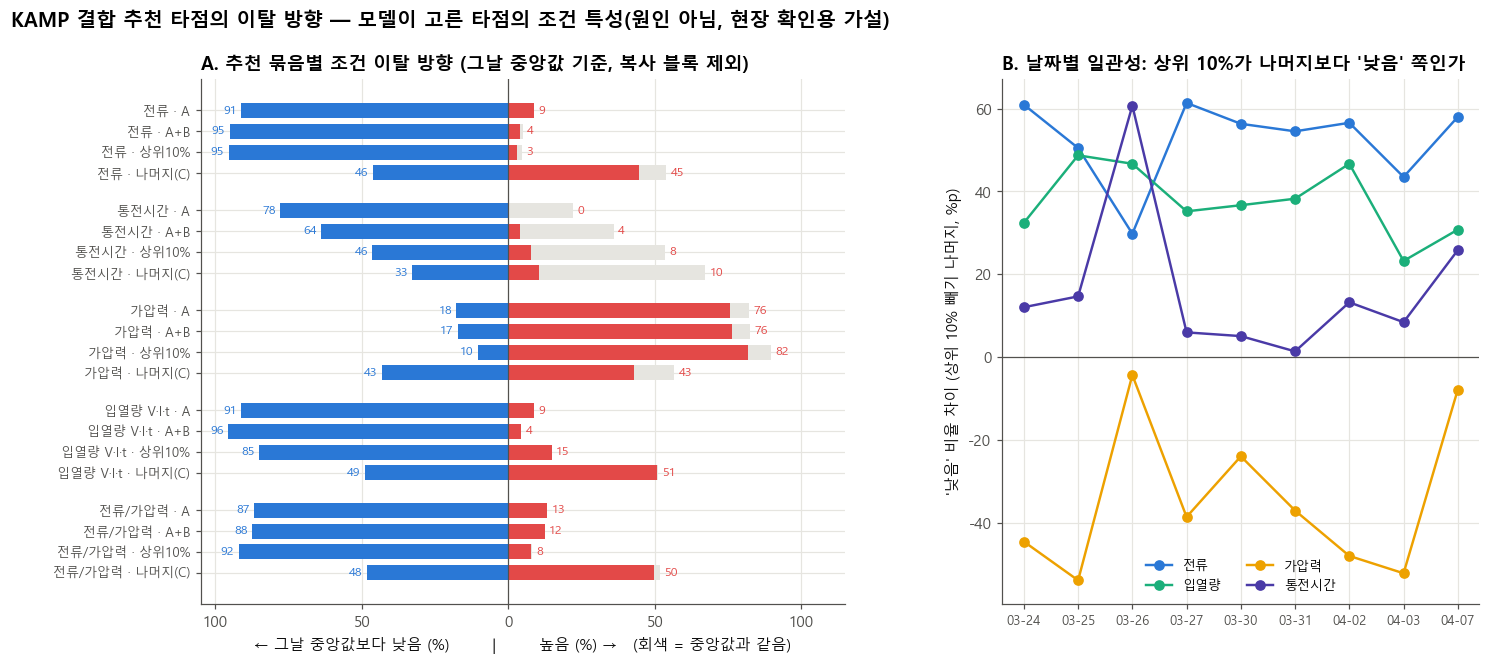

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw=dict(width_ratios=[1.35, 1], wspace=.28))
ax = axs[0]
show = [("cur", "전류"), ("time", "통전시간"), ("force", "가압력"), ("heat", "입열량 V·I·t"), ("IF", "전류/가압력")]
sets = [("grpA", "A"), ("grpAB", "A+B"), ("grp10", "상위10%"), (None, "나머지(C)")]
ylab, y = [], 0; yt = []
for c, cname in show:
    for g, gn in sets:
        sub = K[K[g]] if g else K[K["결합 등급"] == "C"]
        lo_, eq_, hi_ = [(sub[f"{c}_dir"] == v).mean() * 100 for v in (-1, 0, 1)]
        ax.barh(y, -lo_, color=P.PAL[0], height=.72); ax.barh(y, hi_, color=P.PAL[7], height=.72)
        ax.barh(y, eq_, left=hi_, color=P.GRID, height=.72)
        ax.text(-lo_ - 1.5, y, f"{lo_:.0f}", va="center", ha="right", fontsize=8, color=P.PAL[0])
        ax.text(hi_ + eq_ + 1.5, y, f"{hi_:.0f}", va="center", ha="left", fontsize=8, color=P.PAL[7])
        yt.append(y); ylab.append(f"{cname} · {gn}"); y += 1
    y += .8
ax.set_yticks(yt); ax.set_yticklabels(ylab, fontsize=8.5); ax.invert_yaxis(); ax.axvline(0, color=P.INK2, lw=.8)
ax.set_xlim(-105, 115); ax.set_xticks([-100, -50, 0, 50, 100]); ax.set_xticklabels(["100", "50", "0", "50", "100"])
ax.set_xlabel("← 그날 중앙값보다 낮음 (%)        |        높음 (%) →   (회색 = 중앙값과 같음)")
ax.set_title("A. 추천 묶음별 조건 이탈 방향 (그날 중앙값 기준, 복사 블록 제외)", loc="left", fontweight="bold")
ax = axs[1]
days = sorted(K.date.unique())
for (c, cname), col in zip([("cur", "전류"), ("heat", "입열량"), ("force", "가압력"), ("time", "통전시간")], [P.PAL[0], P.PAL[2], P.PAL[3], P.PAL[6]]):
    v = [((K[(K.date == d) & K.grp10][f"{c}_dir"] == -1).mean() - (K[(K.date == d) & ~K.grp10][f"{c}_dir"] == -1).mean()) * 100 for d in days]
    ax.plot(range(len(days)), v, "o-", color=col, label=cname, lw=1.6)
ax.axhline(0, color=P.INK2, lw=.8); ax.set_xticks(range(len(days))); ax.set_xticklabels([d[5:] for d in days], fontsize=8.5)
ax.set_ylabel("'낮음' 비율 차이 (상위 10% 빼기 나머지, %p)"); ax.legend(fontsize=8.5, ncol=2)
ax.set_title("B. 날짜별 일관성: 상위 10%가 나머지보다 '낮음' 쪽인가", loc="left", fontweight="bold")
fig.suptitle("KAMP 결합 추천 타점의 이탈 방향 — 모델이 고른 타점의 조건 특성(원인 아님, 현장 확인용 가설)", x=.01, ha="left", fontsize=13, fontweight="bold")
P.save(fig, "23_kamp_direction"); plt.show()

## 4. 불량 유형별 개수와의 비교 (작업 5)
- 모델 학습에 쓴 정답: `wl/kamp.py`의 `load_kamp()`가 `result` 시트의 `defect`를 **날짜별로 합한 총 개수**만 반환한다. raw PVC는 이 총 개수로 날짜 하나 빼기 학습, D4는 정답 미사용. `defect type` 열은 budget_repro에서 읽지 않는다.
  → 유형별 개수는 모델이 보지 않은 정보다. 단 **A등급 크기는 그날 총 불량 수(c_d)와 같고, B등급은 5c_d**라서 A·A+B 추천 "개수"는 총 개수와 기계적으로 연결된다. 그래서 주 분석은 (i) 상위 10% 개수와 (ii) 추천 안의 방향 비율(묶음 크기와 무관) 대 유형 비율로 한다.
- 날짜는 8개(3/27은 정답 없음). 정확 순열 검정(8! = 40,320가지 전부). 판별력이 매우 낮다. 여러 조합을 봤으므로 다중 비교도 보정하지 않았다.

In [7]:
res = pd.read_excel(wldata.KAMP_XLSX, sheet_name="result")
TY = res.pivot_table(index=res["working time"].dt.strftime("%Y-%m-%d"), columns="defect type", values="defect", aggfunc="sum").fillna(0).astype(int)
TY.columns = [{1: "파임", 2: "용접부족", 3: "크랙"}[c] for c in TY.columns]
TY["파임+크랙"] = TY.파임 + TY.크랙; TY["합계"] = TY[["파임", "용접부족", "크랙"]].sum(1)
TY["용접부족 비율"] = TY.용접부족 / TY.합계; TY["파임+크랙 비율"] = TY["파임+크랙"] / TY.합계
TY["타점 수(순위 대상)"] = K.groupby("date").size().reindex(TY.index)
for g, gname in GROUPS:
    s = K[K[g]].groupby("date")
    TY[f"{gname} 입열낮음 수"] = s.apply(lambda x: (x.heat_dir < 0).sum()).reindex(TY.index)
    TY[f"{gname} 입열높음 수"] = s.apply(lambda x: (x.heat_dir > 0).sum()).reindex(TY.index)
    TY[f"{gname} 입열낮음 비율"] = TY[f"{gname} 입열낮음 수"] / s.size().reindex(TY.index)
    TY[f"{gname} 전류낮음 비율"] = s.apply(lambda x: (x.cur_dir < 0).mean()).reindex(TY.index)
display(TY.round(2))
TY.to_csv(br.RES / "kamp_type_vs_direction_daily.csv", encoding="utf-8-sig")

,파임,용접부족,크랙,파임+크랙,합계,용접부족 비율,파임+크랙 비율,타점 수(순위 대상),A등급 입열낮음 수,A등급 입열높음 수,A등급 입열낮음 비율,A등급 전류낮음 비율,A+B등급 입열낮음 수,A+B등급 입열높음 수,A+B등급 입열낮음 비율,A+B등급 전류낮음 비율,상위 10% 입열낮음 수,상위 10% 입열높음 수,상위 10% 입열낮음 비율,상위 10% 전류낮음 비율
working time,,,,,,,,,,,,,,,,,,,,
2020-03-24,2,1,1,3,4,0.25,0.75,1200,4,0,1.0,1.0,18,2,0.90,1.00,95,25,0.79,1.00
2020-03-25,3,2,3,6,8,0.25,0.75,1061,8,0,1.0,1.0,40,0,1.00,1.00,100,7,0.93,0.95
2020-03-26,3,2,2,5,7,0.29,0.71,1000,7,0,1.0,1.0,35,0,1.00,0.86,92,8,0.92,0.76
2020-03-30,1,2,1,2,4,0.50,0.50,1470,4,0,1.0,1.0,20,0,1.00,1.00,122,25,0.83,1.00
2020-03-31,2,3,0,2,5,0.60,0.40,1509,5,0,1.0,1.0,24,1,0.96,1.00,127,24,0.84,0.95
2020-04-02,1,1,2,3,4,0.25,0.75,2000,4,0,1.0,1.0,20,0,1.00,1.00,184,16,0.92,1.00
2020-04-03,2,1,1,3,4,0.25,0.75,509,0,4,0.0,0.0,13,7,0.65,0.70,36,15,0.71,0.86
2020-04-07,0,1,2,2,3,0.33,0.67,669,3,0,1.0,1.0,15,0,1.00,1.00,52,15,0.78,0.97


In [8]:
tests = []
def add(label, x, y, kind):
    r, p2, p1 = T.perm_spearman(TY[x].values, TY[y].values)
    tests.append({"구분": kind, "비교": label, "x": x, "y": y, "ρ": r, "순열 p(양측)": p2, "순열 p(단측, 기대 방향 +)": p1})
for g, gname in GROUPS:
    kind = "주 분석" if g == "grp10" else "참고(묶음 크기 = 총 불량 수에 연동)"
    add(f"{gname}: 입열낮음 수 vs 용접부족 수", f"{gname} 입열낮음 수", "용접부족", kind)
    add(f"{gname}: 입열높음 수 vs 파임+크랙 수", f"{gname} 입열높음 수", "파임+크랙", kind)
    add(f"{gname}: 입열높음 수 vs 파임 수", f"{gname} 입열높음 수", "파임", kind)
    add(f"{gname}: 입열높음 수 vs 크랙 수", f"{gname} 입열높음 수", "크랙", kind)
    add(f"{gname}: 입열낮음 비율 vs 용접부족 비율", f"{gname} 입열낮음 비율", "용접부족 비율", "주 분석(비율, 크기 무관)")
    add(f"{gname}: 전류낮음 비율 vs 용접부족 비율", f"{gname} 전류낮음 비율", "용접부족 비율", "주 분석(비율, 크기 무관)")
    add(f"[대조] {gname}: 입열낮음 수 vs 파임+크랙 수", f"{gname} 입열낮음 수", "파임+크랙", "교차 대조(방향이 맞다면 약해야 함)")
    add(f"[대조] {gname}: 입열높음 수 vs 용접부족 수", f"{gname} 입열높음 수", "용접부족", "교차 대조(방향이 맞다면 약해야 함)")
add("[기준] 타점 수 vs 용접부족 수", "타점 수(순위 대상)", "용접부족", "기준(하루 생산량만으로 설명되는 정도)")
add("[기준] 타점 수 vs 파임+크랙 수", "타점 수(순위 대상)", "파임+크랙", "기준(하루 생산량만으로 설명되는 정도)")
add("[기준] 총 불량 수 vs 용접부족 수", "합계", "용접부족", "기준(A·A+B 개수 연동 확인)")
add("[기준] 총 불량 수 vs A등급 입열낮음 수", "합계", "A등급 입열낮음 수", "기준(A·A+B 개수 연동 확인)")
add("[기준] 타점 수 vs 상위10% 입열낮음 수", "타점 수(순위 대상)", "상위 10% 입열낮음 수", "기준(하루 생산량만으로 설명되는 정도)")
TT = pd.DataFrame(tests).round(3)
display(TT.drop(columns=["x", "y"]))
TT.to_csv(br.RES / "kamp_type_vs_direction_tests.csv", index=False, encoding="utf-8-sig")
print("판별력 참고: 날짜 8개에서 순열 단측 p<0.05가 되려면 ρ가 약 +0.64 이상이어야 한다(동점 없을 때).")

,구분,비교,ρ,순열 p(양측),"순열 p(단측, 기대 방향 +)"
0,참고(묶음 크기 = 총 불량 수에 연동),A등급: 입열낮음 수 vs 용접부족 수,0.735,0.054,0.032
1,참고(묶음 크기 = 총 불량 수에 연동),A등급: 입열높음 수 vs 파임+크랙 수,0.087,1.000,0.625
2,참고(묶음 크기 = 총 불량 수에 연동),A등급: 입열높음 수 vs 파임 수,0.086,1.000,0.625
3,참고(묶음 크기 = 총 불량 수에 연동),A등급: 입열높음 수 vs 크랙 수,-0.260,1.000,0.875
4,"주 분석(비율, 크기 무관)",A등급: 입열낮음 비율 vs 용접부족 비율,0.351,0.750,0.500
5,"주 분석(비율, 크기 무관)",A등급: 전류낮음 비율 vs 용접부족 비율,0.351,0.750,0.500
6,교차 대조(방향이 맞다면 약해야 함),[대조] A등급: 입열낮음 수 vs 파임+크랙 수,0.513,0.207,0.109
7,교차 대조(방향이 맞다면 약해야 함),[대조] A등급: 입열높음 수 vs 용접부족 수,-0.361,0.625,1.000
8,참고(묶음 크기 = 총 불량 수에 연동),A+B등급: 입열낮음 수 vs 용접부족 수,0.767,0.043,0.021
9,참고(묶음 크기 = 총 불량 수에 연동),A+B등급: 입열높음 수 vs 파임+크랙 수,-0.086,0.902,0.625


판별력 참고: 날짜 8개에서 순열 단측 p<0.05가 되려면 ρ가 약 +0.64 이상이어야 한다(동점 없을 때).
